# Wisata Madura — Input → Proses → Output (v3)
**Malik Hariyanto · Asistensi Hibah Penelitian**

Notebook pembelajaran: **input data → audit/EDA → split → pemodelan topik LDA → embedding FastText → modeling BiLSTM → evaluasi → output**.

Dataset terbaru: **2.058 ulasan, 27 destinasi Madura**. Semua angka split, jumlah topik, dimensi, dan metrik ditampilkan dari run aktual. Angka 79.514/207 dan K=2 pada diagram lama bukan konstanta eksperimen ini.

Jalankan dari atas. Bagian 00–05 tidak melatih BiLSTM; bagian 06–07 melatih embedding dan classifier; test dilaporkan di bagian 08. **LDA menghasilkan distribusi topik, FastText menghasilkan embedding, dan BiLSTM memprediksi dua atribut:** kecocokan cuaca serta jenis wisata. Bukan klasifikasi sentimen atau validasi musim kunjungan.

[Landasan paper dan batas adaptasi](https://github.com/MalikHariyanto/crispy_recom_machine_system/blob/feat/streamlit-wisata/docs/METODOLOGI_DAN_PAPER.md) · [Panduan v3](https://github.com/MalikHariyanto/crispy_recom_machine_system/blob/feat/streamlit-wisata/docs/COLAB_V3.md).

## 00 · Setup dan konfigurasi

**Input:** Repository, pilihan mode, seed yang ditetapkan sebelum eksperimen.

**Proses:** Pasang dependensi; tetapkan anggaran komputasi dan folder run.

**Output:** Modul siap dipakai, konfigurasi eksplisit, hash kode.

`MODE="full"`: grid LDA 6 K × 3 seed, BiLSTM hingga 15 epoch × 3 seed. GPU Colab disarankan. `MODE="smoke"`: tes alur cepat, **bukan hasil penelitian final**. Hiperparameter adalah pilihan lokal, bukan nilai optimal yang dijamin jurnal. Gunakan runtime baru jika pernah mengimpor versi kode sebelumnya.

In [1]:
from pathlib import Path
from datetime import datetime
import subprocess, sys, os, hashlib, json

MODE = "full"  # "full" atau "smoke"
RUN_DEEP = True
SEED = 42
DATA_PATH = None  # None: dataset Madura otomatis, tanpa upload.
OUTPUT_DIR = Path("hasil_wisata_madura_v3") / datetime.now().strftime("%Y%m%d-%H%M%S-%f")
BRANCH = "feat/streamlit-wisata"
REPOSITORY = "https://github.com/MalikHariyanto/crispy_recom_machine_system.git"
if MODE not in {"full", "smoke"}:
    raise ValueError("MODE harus full atau smoke")
checkout = Path.cwd() / "wisata_madura_v3"
repo_root = next((p for p in (Path.cwd(), Path.cwd().parent, checkout)
                  if (p / "src/wisata_madura/protocol.py").is_file()), None)
if repo_root is None:
    if checkout.exists():
        raise FileExistsError("Folder wisata_madura_v3 berisi versi lama. Ganti nama folder atau mulai runtime baru.")
    subprocess.run(["git", "clone", "--depth", "1", "--branch", BRANCH, REPOSITORY, str(checkout)], check=True)
    repo_root = checkout
requirements = ["-r", str(repo_root / "requirements-wisata.txt")]
if RUN_DEEP:
    requirements += ["gensim>=4.4,<5", "torch>=2.2,<3"]
subprocess.run([sys.executable, "-m", "pip", "install", "--disable-pip-version-check", *requirements], check=True)
if any(name.startswith("wisata_madura") for name in sys.modules):
    raise RuntimeError("Modul pernah diimpor. Restart runtime agar kode dan hasil tidak mencampur versi.")
sys.path.insert(0, str(repo_root / "src"))
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str((OUTPUT_DIR / ".matplotlib").resolve()))
source_commit = subprocess.check_output(["git", "-C", str(repo_root), "rev-parse", "HEAD"], text=True).strip()
source_dirty = bool(subprocess.check_output(["git", "-C", str(repo_root), "status", "--porcelain"], text=True).strip())
source_hashes = {p.name: hashlib.sha256(p.read_bytes()).hexdigest()
                 for p in (repo_root / "src/wisata_madura").glob("*.py")}
print("Mode:", MODE, "| Source:", source_commit, "| Output:", OUTPUT_DIR)

Mode: full | Source: 722d07a23376e2f0407425cac22ceb469e9eb429 | Output: hasil_wisata_madura_v3/20261112-131554-444000


## 01 · INPUT: dataset dan label

**Input:** Workbook dataset_madura_bersih.xlsx dan manifest paket data.

**Proses:** Validasi checksum, skema, label per ID; normalisasi ringan teks.

**Output:** DataFrame reviews dengan rating, teks_model, dan dua label.

Kolom `rating` dipakai untuk EDA, **tidak dimasukkan sebagai fitur classifier**. Teks model berasal dari preprocessing sumber; audit tidak membuktikan bahwa seluruh teks/label sumber bebas kesalahan. Cakupan Madura sesuai konfirmasi pemilik data.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from wisata_madura.data import load_reviews, load_bundled_reviews, audit_reviews, TARGETS
from wisata_madura.protocol import SplitConfig, make_experiment_split
from wisata_madura.reporting import StageTrace

trace = StageTrace(OUTPUT_DIR)
if DATA_PATH is None:
    bundled, data_manifest = load_bundled_reviews(repo_root / "data")
    workbook_path = repo_root / "data/source" / data_manifest["source_workbook"]
    if hashlib.sha256(workbook_path.read_bytes()).hexdigest() != data_manifest["source_workbook_sha256"]:
        raise ValueError("Checksum workbook tidak cocok dengan manifest")
    reviews = load_reviews(workbook_path)
    columns = ["id_destinasi", "destinasi", *TARGETS, "teks_model"]
    pd.testing.assert_frame_equal(reviews[columns], bundled[columns])
else:
    workbook_path = Path(DATA_PATH)
    reviews = load_reviews(workbook_path)
    data_manifest = None
print(f"INPUT: {len(reviews):,} ulasan / {reviews.id_destinasi.nunique()} destinasi")
display(reviews[["destinasi", "rating", "teks_model", *TARGETS]].head())
display(trace.record("01 Input", workbook_path.name, "validasi + normalisasi", f"reviews {reviews.shape}"))

INPUT: 2,058 ulasan / 27 destinasi


,destinasi,rating,teks_model,rekomendasi_cuaca,wisata
0,Air Terjun Toroan,5,toro waterfall in ketapang district sampang re...,Kemarau & Penghujan,air terjun
1,Air Terjun Toroan,5,makam syaikona kholil bangkal sore mampir pant...,Kemarau & Penghujan,air terjun
2,Air Terjun Toroan,5,air terjun cukup bagus akses mobil sangat muda...,Kemarau & Penghujan,air terjun
3,Air Terjun Toroan,5,wisata pantai air terjun satusatunya pulau mad...,Kemarau & Penghujan,air terjun
4,Air Terjun Toroan,5,unik sekali air terjun langsung laut lokasi ta...,Kemarau & Penghujan,air terjun


,section,input,proses,output
0,01 Input,dataset_madura_bersih.xlsx,validasi + normalisasi,"reviews (2058, 9)"


## 02 · INPUT: audit dan eksplorasi data

**Input:** reviews sebelum split.

**Proses:** Hitung kualitas data; grafik rating, cuaca, jenis wisata, panjang teks.

**Output:** audit, tabel CSV, grafik PNG.

Batang rating/cuaca menghitung ulasan. Pie cuaca/jenis menghitung **destinasi unik** agar tempat ramai tidak dihitung berkali-kali. EDA seluruh data bersifat deskriptif; aturan pemilihan model tetap berdasarkan train/validation.

,0
file_sha256,09c6127d532bbf8e08e1be79e29795b080a07acd89039b...
rows,2058
destinations,27
empty_by_column,"{'id_destinasi': 0, 'destinasi': 0, 'rating': ..."
exact_duplicate_rows,42
empty_normalized_text_rows,0
relative_date_rows,2058
potential_encoding_error_rows,233
targets,"[rekomendasi_cuaca, wisata]"


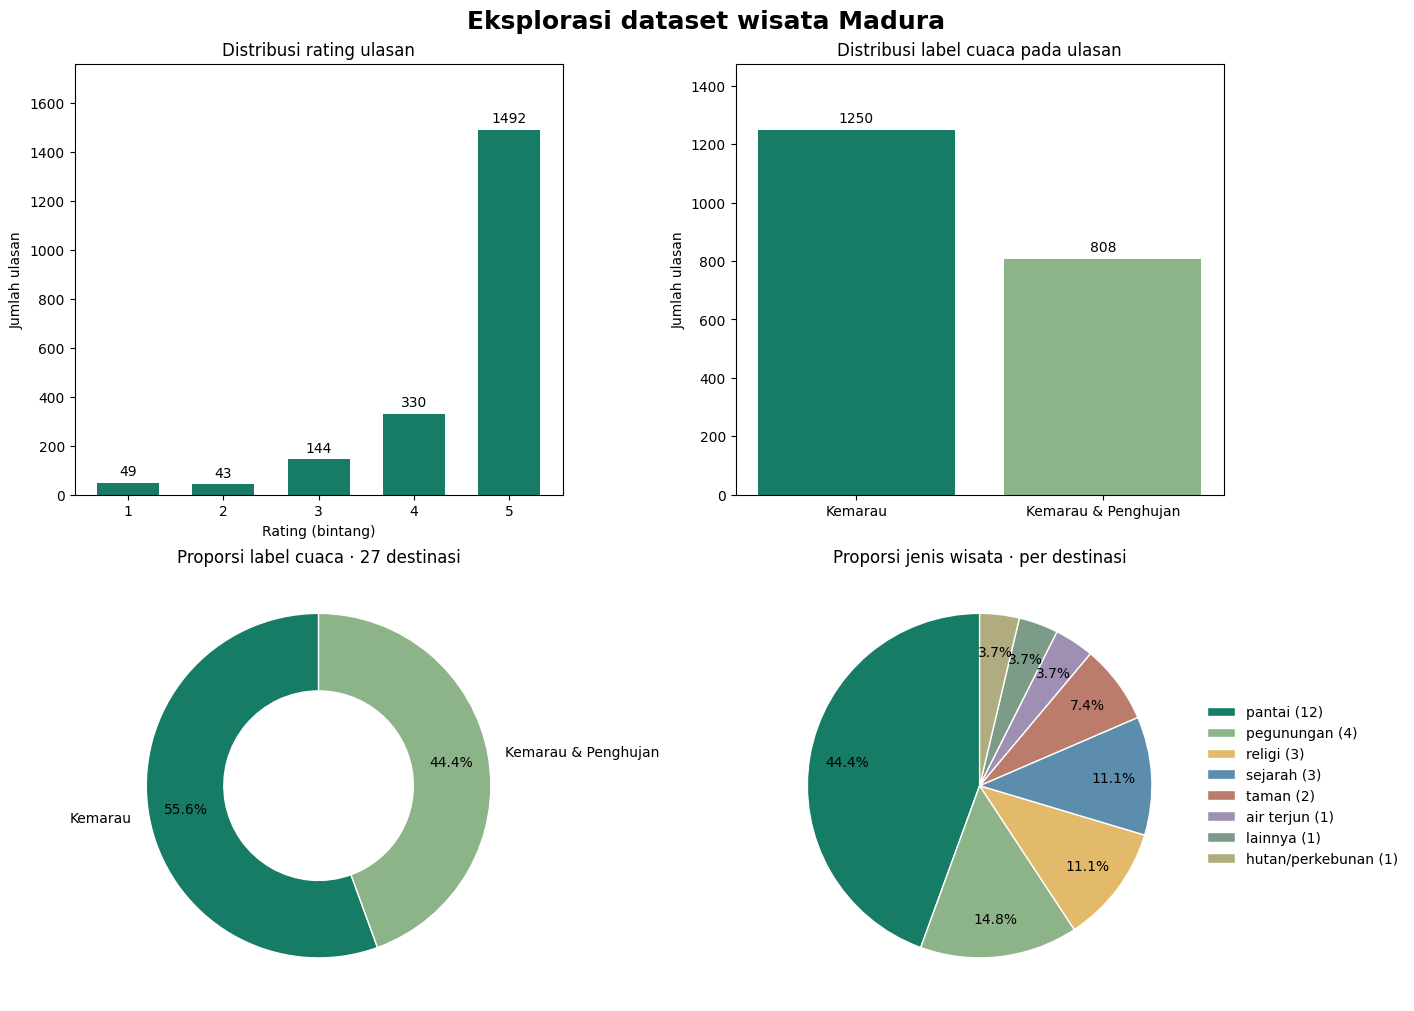

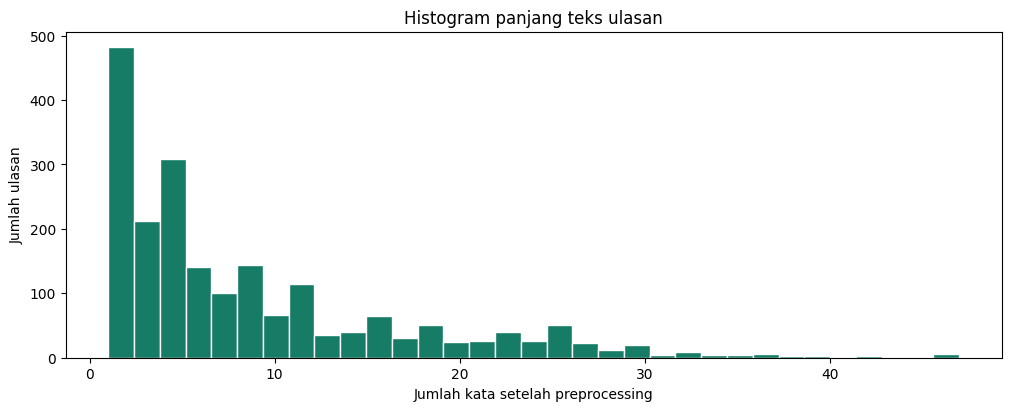

,rating,ulasan,persentase
0,1,49,2.38
1,2,43,2.09
2,3,144,7.00
3,4,330,16.03
4,5,1492,72.50


,cuaca,ulasan,persentase
0,Kemarau,1250,60.74
1,Kemarau & Penghujan,808,39.26


,cuaca,destinasi,persentase
0,Kemarau,15,55.56
1,Kemarau & Penghujan,12,44.44


,jenis_wisata,destinasi,persentase
0,pantai,12,44.44
1,pegunungan,4,14.81
2,religi,3,11.11
3,sejarah,3,11.11
4,taman,2,7.41
5,air terjun,1,3.70
6,lainnya,1,3.70
7,hutan/perkebunan,1,3.70


,section,input,proses,output
1,02 Audit/EDA,2058 ulasan,audit + agregasi per unit,EDA PNG/CSV + audit


In [3]:
from wisata_madura.visualization import plot_dataset_overview, plot_partition_overview

audit = audit_reviews(reviews, workbook_path)
figures, eda_tables = plot_dataset_overview(reviews, OUTPUT_DIR)
display(pd.Series(audit))
for figure in figures:
    display(figure)
    plt.close(figure)
for name in ("rating", "cuaca_ulasan", "cuaca_destinasi", "jenis_destinasi"):
    display(eda_tables[name].round(2))
display(trace.record("02 Audit/EDA", f"{len(reviews)} ulasan", "audit + agregasi per unit", "EDA PNG/CSV + audit"))

## 03 · PROSES: bersihkan dan bagi data

**Input:** reviews dan SplitConfig yang ditetapkan sebelum fitting.

**Proses:** Split kelompok ID destinasi dengan kandidat berbasis metadata; buang teks identik lintas partisi.

**Output:** split.train, split.validation, split.test; cakupan kelas; grafik pembagian.

R06/R17: pemisahan kelompok mencegah kebocoran destinasi; teks identik juga diperiksa. Kandidat split dipilih menggunakan ukuran kelompok dan distribusi label, **tanpa skor model atau fitur hasil belajar**. Target nominal 64/16/20 untuk ulasan; tidak dipaksakan tepat karena kelompok tidak boleh dipecah. Kelas satu destinasi tetap train-only; lihat tabel cakupan. Perubahan protokol berarti hasil v3 tidak dapat dibandingkan dengan v2 seolah hanya arsitektur yang berubah.

,ulasan,destinasi,persen_ulasan,persen_destinasi
partisi,,,,
Train,1168,16,62.73,59.26
Validation,268,5,14.39,18.52
Test,426,6,22.88,22.22


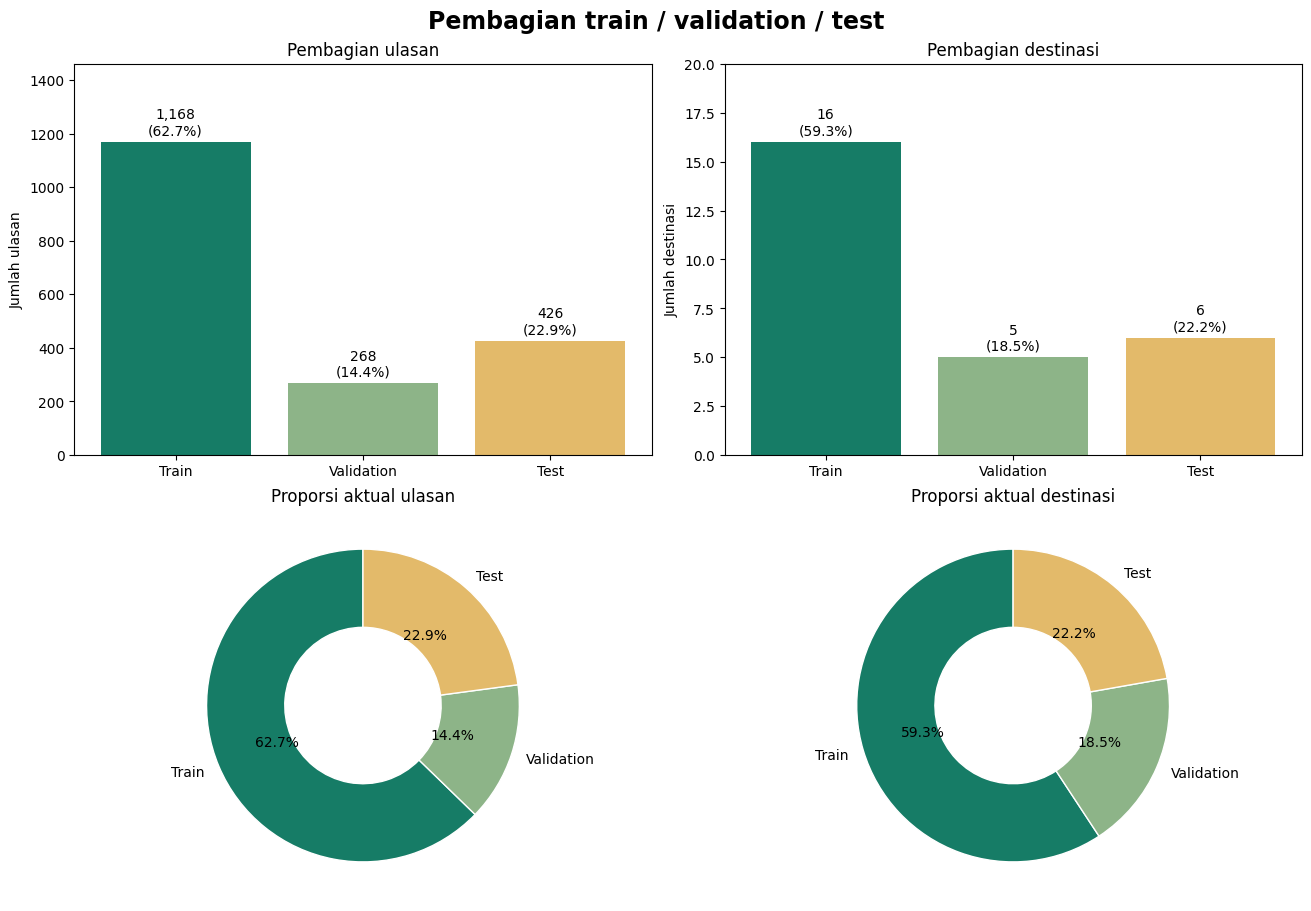

,target,kelas,train_destinasi,validation_destinasi,test_destinasi
0,rekomendasi_cuaca,Kemarau,9,2,4
1,rekomendasi_cuaca,Kemarau & Penghujan,7,3,2
2,wisata,air terjun,1,0,0
3,wisata,hutan/perkebunan,1,0,0
4,wisata,lainnya,1,0,0
5,wisata,pantai,8,2,2
6,wisata,pegunungan,2,1,1
7,wisata,religi,1,1,1
8,wisata,sejarah,1,1,1
9,wisata,taman,1,0,1


Pembersihan: {'input_reviews': 2058, 'empty_removed': 0, 'duplicates_within_destination_removed': 159, 'cross_partition_text_removed': {'train': 0, 'validation': 15, 'test': 22}}
Tujuan metadata split: 0.08723468492188875
Kelas train-only tidak punya bukti generalisasi test. Rasio aktual ada pada tabel di atas.


,section,input,proses,output
2,03 Split,2058 ulasan,kelompok ID + metadata; tanpa skor,"{'train': 1168, 'validation': 268, 'test': 426}"


In [4]:
split_config = SplitConfig(seed=SEED, candidates=2048)
split = make_experiment_split(reviews, split_config, OUTPUT_DIR)
partition_figure, partition_table = plot_partition_overview(split, OUTPUT_DIR)
display(partition_table.round(2))
display(partition_figure)
plt.close(partition_figure)
display(pd.DataFrame(split.audit["class_coverage"]))
print("Pembersihan:", {k: split.audit[k] for k in ("input_reviews", "empty_removed", "duplicates_within_destination_removed", "cross_partition_text_removed")})
print("Tujuan metadata split:", split.audit["metadata_objective"])
print("Kelas train-only tidak punya bukti generalisasi test. Rasio aktual ada pada tabel di atas.")
display(trace.record("03 Split", f"{len(reviews)} ulasan", "kelompok ID + metadata; tanpa skor", str(split.audit["partition_reviews"])))

## 04 · PROSES: pemodelan topik LDA

**Input:** Teks train untuk fit; teks validation untuk seleksi K.

**Proses:** CountVectorizer → LDA kandidat K/seed → NPMI validation → K terpilih.

**Output:** topics (distribusi topik train/validation/test), tabel kata, contoh, model_lda.joblib.

R01–R05: LDA menerima **count kata**, bukan embedding FastText. Kosakata, stopword, dan LDA tidak di-fit pada validation/test. NPMI yang dipakai berbasis dokumen, **bukan c_v**. Perplexity/diversity/stability adalah diagnostik tambahan. K yang menang dalam grid tidak membuktikan topiknya koheren; skor negatif dan topik lemah tetap dilaporkan. Transform test memakai model beku dan tidak menentukan pemilihan K.

LDA K=2, seed=42: validation NPMI=-0.5559, perplexity=1145.3
LDA K=2, seed=43: validation NPMI=-0.5381, perplexity=1173.7
LDA K=2, seed=44: validation NPMI=-0.5566, perplexity=1224.2
LDA K=4, seed=42: validation NPMI=-0.6439, perplexity=3245.0
LDA K=4, seed=43: validation NPMI=-0.6831, perplexity=3754.5
LDA K=4, seed=44: validation NPMI=-0.6389, perplexity=3801.4
LDA K=6, seed=42: validation NPMI=-0.7155, perplexity=8245.6
LDA K=6, seed=43: validation NPMI=-0.6858, perplexity=9345.1
LDA K=6, seed=44: validation NPMI=-0.7114, perplexity=9403.4
LDA K=8, seed=42: validation NPMI=-0.7237, perplexity=17520.1
LDA K=8, seed=43: validation NPMI=-0.7555, perplexity=15542.3
LDA K=8, seed=44: validation NPMI=-0.6897, perplexity=22080.3
LDA K=10, seed=42: validation NPMI=-0.8328, perplexity=23334.4
LDA K=10, seed=43: validation NPMI=-0.7440, perplexity=23577.0
LDA K=10, seed=44: validation NPMI=-0.7386, perplexity=27357.7
LDA K=12, seed=42: validation NPMI=-0.7147, perplexity=79791.7
LDA K=12, see

,n_topics,validation_npmi_mean,validation_npmi_std,validation_perplexity_mean,topic_diversity_mean,stability_jaccard
0,2,-0.5502,0.0105,1181.0453,0.8500,0.4400
1,4,-0.6553,0.0242,3600.3070,0.7500,0.4031
2,6,-0.7042,0.0161,8998.0601,0.6944,0.2834
3,8,-0.7230,0.0329,18380.8921,0.7458,0.2315
4,12,-0.7661,0.0508,56103.0031,0.6667,0.2351
5,10,-0.7718,0.0529,24756.3472,0.7467,0.2567


K terpilih dari run ini: 2
Bentuk fitur LDA: (1168, 2) (268, 2) (426, 2)


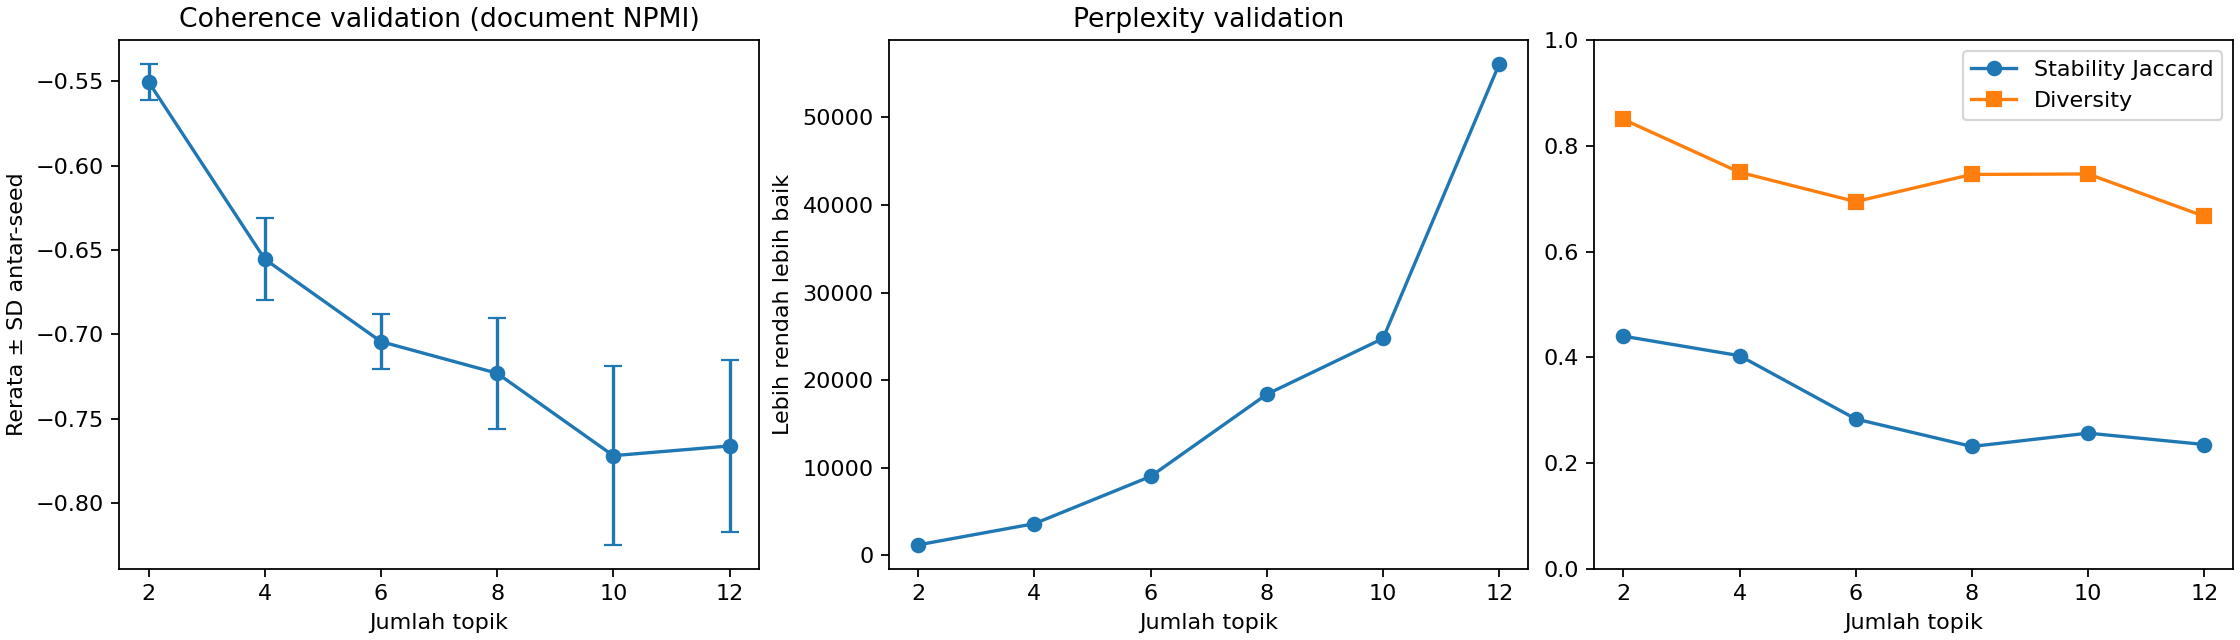

,section,input,proses,output
3,04 LDA,"train=1168, validation=268",fit count/LDA di train; seleksi validation,"K=2; theta=(1168, 2)"


In [5]:
from wisata_madura.topics import TopicConfig, analyze_topics
from dataclasses import asdict
from IPython.display import Image

topic_config = TopicConfig(
    topic_counts=(2,4,6,8,10,12) if MODE == "full" else (2,3),
    seeds=(42,43,44) if MODE == "full" else (42,43),
    max_iter=20 if MODE == "full" else 2,
)
topics, topic_tables, lda_audit = analyze_topics(split, OUTPUT_DIR, topic_config)
display(topic_tables["pemilihan_topik"].round(4))
print("K terpilih dari run ini:", lda_audit["selected_topics"])
print("Bentuk fitur LDA:", topics.train.shape, topics.validation.shape, topics.test.shape)
display(Image(filename=str(OUTPUT_DIR / "pemilihan_topik.png")))
display(trace.record("04 LDA", f"train={len(split.train)}, validation={len(split.validation)}", "fit count/LDA di train; seleksi validation", f"K={lda_audit['selected_topics']}; theta={topics.train.shape}"))

## 05 · PROSES: pelajari dan interpretasikan keluaran LDA

**Input:** Model dan topic_tables hasil section 04.

**Proses:** Baca bobot kata, contoh ulasan, diagnosis topik lemah.

**Output:** Bahan interpretasi dan template_review_topik.csv.

ID topik tidak otomatis berarti aspek atau sentimen. Isi nama topik secara manual setelah membaca contoh. Rerata cuaca adalah deskripsi, bukan hubungan sebab-akibat. Model LDA dipakai ulang; section ini tidak melatih LDA lagi.

,topik,kata_utama
0,topik_1,"madura, wisata, tempat, pantai, pamekasan, bag..."
1,topik_2,"madura, pantai, air, terjun, bangkal, pulau, i..."


,topik,kata_utama,validation_npmi,rata_rata_bobot_train,dokumen_dominan_train
0,topik_1,"madura, wisata, tempat, pantai, pamekasan, bag...",-0.414078,0.624675,225
1,topik_2,"madura, pantai, air, terjun, bangkal, pulau, i...",-0.697784,0.375325,106


,topik,bobot,id_destinasi,destinasi,teks_model,asal
0,topik_1,0.973559,108,Mercusuar Sembilang,mercusuar bangkal letak ujung barat pulau madu...,train_sample
1,topik_1,0.972807,168,Puncak Ratu,puncak ratu rupa wisata lokal kota pamekasan c...,train_sample
2,topik_1,0.972288,108,Mercusuar Sembilang,bangun sejarah bangun tahun fungsi pantau pant...,train_sample
3,topik_1,0.972098,29,Bukit Jadih,wisata bangkal madura dulu sempat viral cukup ...,train_sample
4,topik_1,0.971833,29,Bukit Jadih,salah satu alternatif wisata pulau madura buki...,train_sample
5,topik_2,0.980257,19,Air Terjun Toroan,air terjun toro satu satu air terjun madura ma...,train_sample
6,topik_2,0.973401,19,Air Terjun Toroan,hidden gem madura cukup jarang dapat air terju...,train_sample
7,topik_2,0.967170,148,Pantai Lon Malang,pantai lon malang sangat indah sunset pantai a...,train_sample
8,topik_2,0.965473,148,Pantai Lon Malang,pantai lon malang salah satu pantai sedang hit...,train_sample
9,topik_2,0.959150,19,Air Terjun Toroan,air terjun toro pinggir laut utara pulau madur...,train_sample


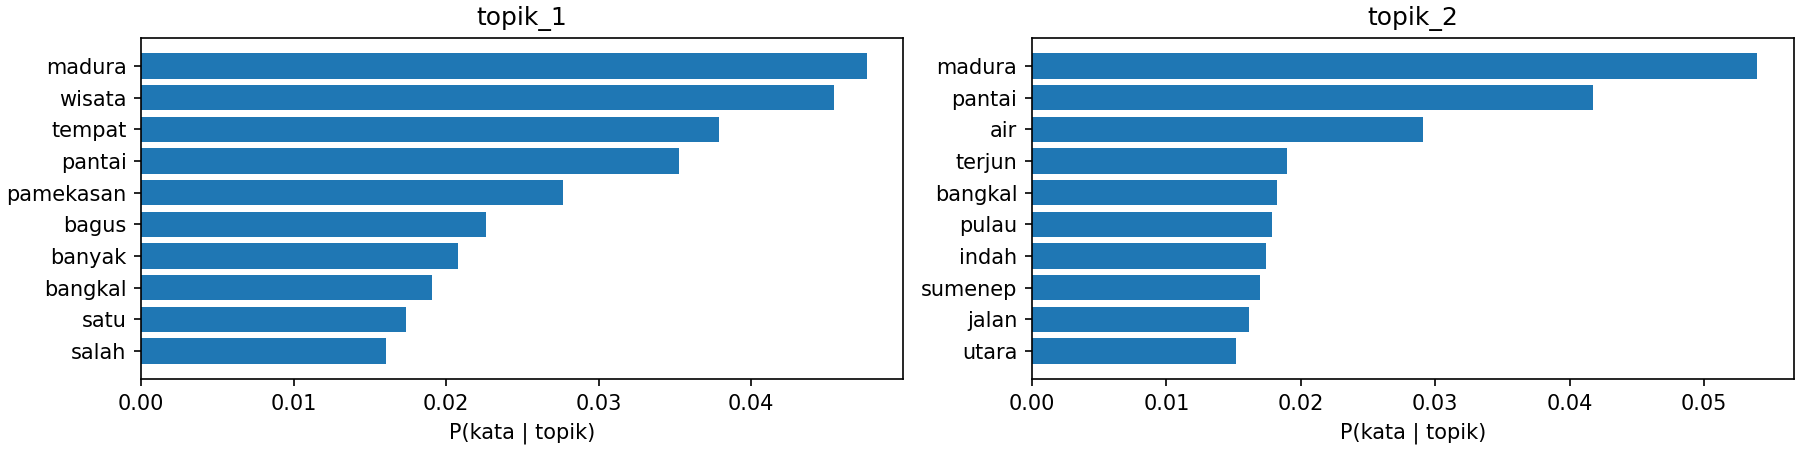

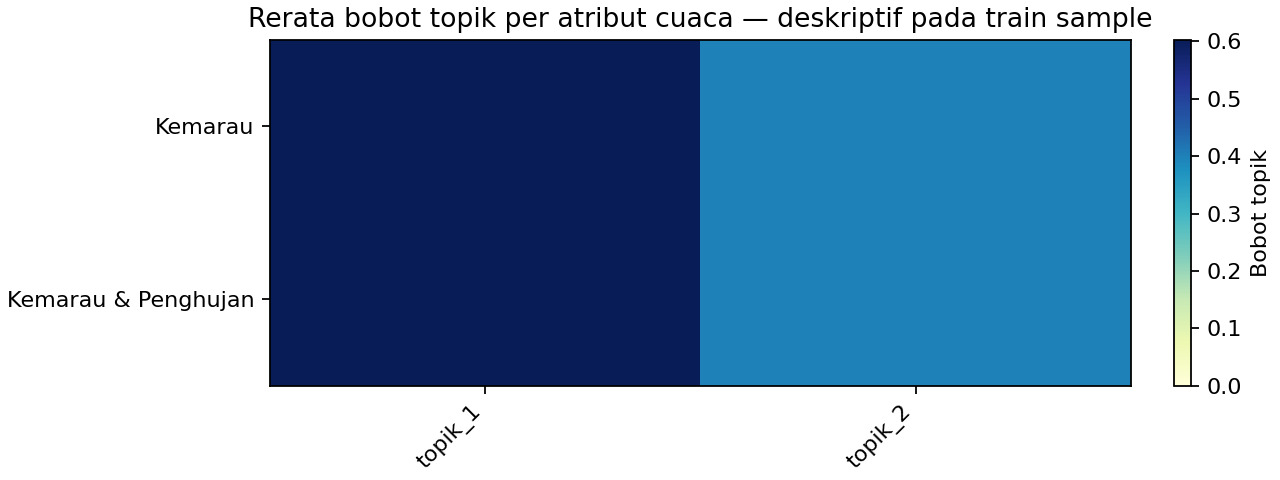

Diagnosis: {'negative_npmi_topics': ['topik_1', 'topik_2'], 'selected_k_at_grid_boundary': True, 'stability_jaccard': 0.44004280033691795, 'note': 'Relative best within this grid only; human interpretation is still required.'}


In [6]:
display(topic_tables["topik_lda"])
display(topic_tables["kualitas_topik"])
display(topic_tables["contoh_ulasan_topik"])
display(Image(filename=str(OUTPUT_DIR / "kata_utama_topik.png")))
display(Image(filename=str(OUTPUT_DIR / "heatmap_topik_cuaca.png")))
print("Diagnosis:", lda_audit["diagnostics"])

## 06 · PROSES: embedding FastText

**Input:** Teks train dan seed yang sudah ditentukan.

**Proses:** Tokenisasi → skip-gram subword 3–6 → token IDs dan matriks embedding beku.

**Output:** EncodedReviews per seed, fasttext.model, embedding_matrix.npy, token_ids.json.

R07/R13: FastText dilatih **sekali per seed pada train**, lalu dipakai bersama oleh kedua ablation BiLSTM. Validation/test hanya di-encode dengan FastText beku; kata baru memakai subword. Penambahan ID token holdout hanya lookup vektor beku, bukan fit embedding. Mode full memakai tiga seed untuk variasi embedding+BiLSTM, bukan tiga split atau tiga dataset.

In [7]:
encoded_by_seed = {}
deep_configs = {}
training_seeds = (42,43,44) if MODE == "full" else (42,)
if RUN_DEEP:
    from wisata_madura.neural import DeepConfig, fit_fasttext, run_bilstm_variants, plot_training_history
    for training_seed in training_seeds:
        config = DeepConfig(seed=training_seed, bilstm_epochs=15 if MODE == "full" else 2,
                            patience=3 if MODE == "full" else 1, balance_destinations=True)
        deep_configs[training_seed] = config
        seed_dir = OUTPUT_DIR / "models" / f"seed_{training_seed}"
        encoded = fit_fasttext(split, config, seed_dir)
        encoded_by_seed[training_seed] = encoded
        print(f"Seed {training_seed}: token train={encoded.train_tokens.shape}; embedding={encoded.embeddings.shape}")
        print("Contoh 12 token IDs:", encoded.train_tokens[0, :12])
        print("PAD ID 0; embedding frozen; dimensi:", config.embedding_dim)
    display(trace.record("06 Embedding", f"{len(split.train)} ulasan train", "FastText train-only, satu kali per seed", f"{len(encoded_by_seed)} embedding beku"))
else:
    print("RUN_DEEP=False: embedding/BiLSTM dilewati; bukan eksperimen arsitektur lengkap.")

Seed 42: token train=(1168, 64); embedding=(3381, 80)
Contoh 12 token IDs: [ 1  2  3  4  5  6  7  8  9 10 11 12]
PAD ID 0; embedding frozen; dimensi: 80
Seed 43: token train=(1168, 64); embedding=(3381, 80)
Contoh 12 token IDs: [ 1  2  3  4  5  6  7  8  9 10 11 12]
PAD ID 0; embedding frozen; dimensi: 80
Seed 44: token train=(1168, 64); embedding=(3381, 80)
Contoh 12 token IDs: [ 1  2  3  4  5  6  7  8  9 10 11 12]
PAD ID 0; embedding frozen; dimensi: 80


,section,input,proses,output
4,06 Embedding,1168 ulasan train,"FastText train-only, satu kali per seed",3 embedding beku


## 07 · PROSES: modeling classifier dan ablation

**Input:** Fitur LDA dan embedding beku; label train; validation untuk checkpoint.

**Proses:** Pembanding klasik + BiLSTM tanpa LDA + BiLSTM dengan concatenation LDA.

**Output:** Prediksi test per seed/model (belum dievaluasi), riwayat loss, checkpoint terbaik.

R08–R16: dua kepala klasifikasi (cuaca/jenis), dropout, Adam, clipping, early stopping. Bobot kelas dihitung dari **destinasi train**; bobot sampel mengimbangi jumlah ulasan per destinasi. Validation loss memakai bobot kelas train dan bobot unit destinasi validation. Ini mengurangi dominasi kelompok, bukan menjamin bebas bias. Pembanding klasik fit sekali, bukan diulang untuk menggandakan jumlah seed. Kedua ablation deep berbagi embedding dan partisi; checkpoint dipilih dari validation, tidak dari test.

fasttext_bilstm | epoch 1/15 | train=1.3944 | validation=1.5122
fasttext_bilstm | epoch 2/15 | train=1.3910 | validation=1.5066
fasttext_bilstm | epoch 3/15 | train=1.3843 | validation=1.5006
fasttext_bilstm | epoch 4/15 | train=1.3832 | validation=1.4933
fasttext_bilstm | epoch 5/15 | train=1.3820 | validation=1.4853
fasttext_bilstm | epoch 6/15 | train=1.3811 | validation=1.4787
fasttext_bilstm | epoch 7/15 | train=1.3737 | validation=1.4906
fasttext_bilstm | epoch 8/15 | train=1.3670 | validation=1.4959
fasttext_bilstm | epoch 9/15 | train=1.3530 | validation=1.4859
Early stopping; best epoch=6
fasttext_lda_bilstm | epoch 1/15 | train=1.3967 | validation=1.5208
fasttext_lda_bilstm | epoch 2/15 | train=1.3882 | validation=1.5123
fasttext_lda_bilstm | epoch 3/15 | train=1.3873 | validation=1.5032
fasttext_lda_bilstm | epoch 4/15 | train=1.3857 | validation=1.4942
fasttext_lda_bilstm | epoch 5/15 | train=1.3806 | validation=1.4827
fasttext_lda_bilstm | epoch 6/15 | train=1.3783 | valid

,model,best_epoch,best_validation_loss,epochs_executed,device
0,fasttext_bilstm,6,1.478688,9,cuda
1,fasttext_lda_bilstm,6,1.468946,9,cuda


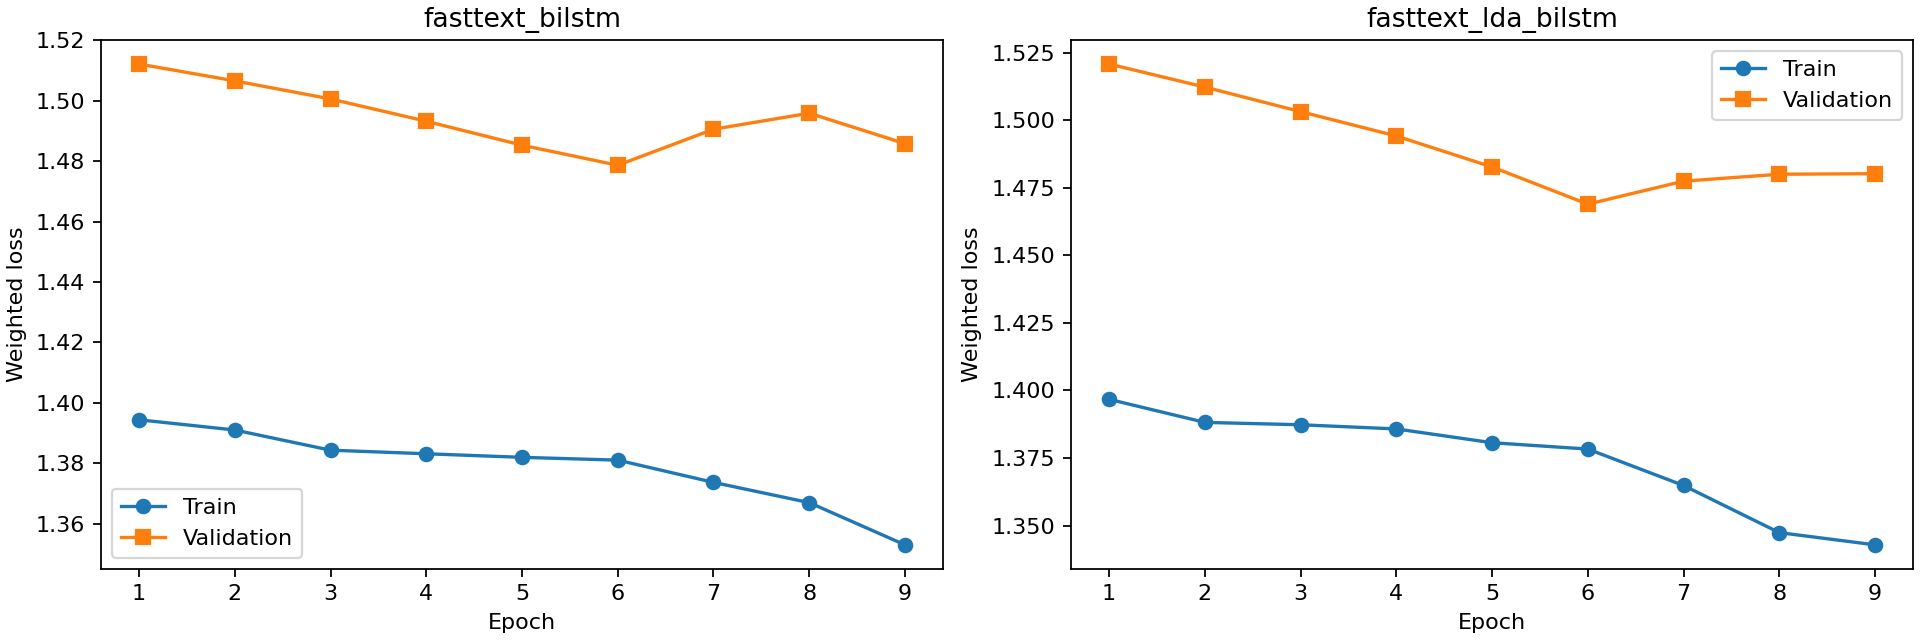

fasttext_bilstm | epoch 1/15 | train=1.3933 | validation=1.4929
fasttext_bilstm | epoch 2/15 | train=1.3875 | validation=1.5038
fasttext_bilstm | epoch 3/15 | train=1.3887 | validation=1.5017
fasttext_bilstm | epoch 4/15 | train=1.3846 | validation=1.5019
Early stopping; best epoch=1
fasttext_lda_bilstm | epoch 1/15 | train=1.3924 | validation=1.5109
fasttext_lda_bilstm | epoch 2/15 | train=1.3851 | validation=1.5179
fasttext_lda_bilstm | epoch 3/15 | train=1.3827 | validation=1.5087
fasttext_lda_bilstm | epoch 4/15 | train=1.3827 | validation=1.5023
fasttext_lda_bilstm | epoch 5/15 | train=1.3812 | validation=1.4999
fasttext_lda_bilstm | epoch 6/15 | train=1.3776 | validation=1.4832
fasttext_lda_bilstm | epoch 7/15 | train=1.3685 | validation=1.4561
fasttext_lda_bilstm | epoch 8/15 | train=1.3599 | validation=1.4730
fasttext_lda_bilstm | epoch 9/15 | train=1.3423 | validation=1.5007
fasttext_lda_bilstm | epoch 10/15 | train=1.3352 | validation=1.4787
Early stopping; best epoch=7


,model,best_epoch,best_validation_loss,epochs_executed,device
0,fasttext_bilstm,1,1.492933,4,cuda
1,fasttext_lda_bilstm,7,1.456139,10,cuda


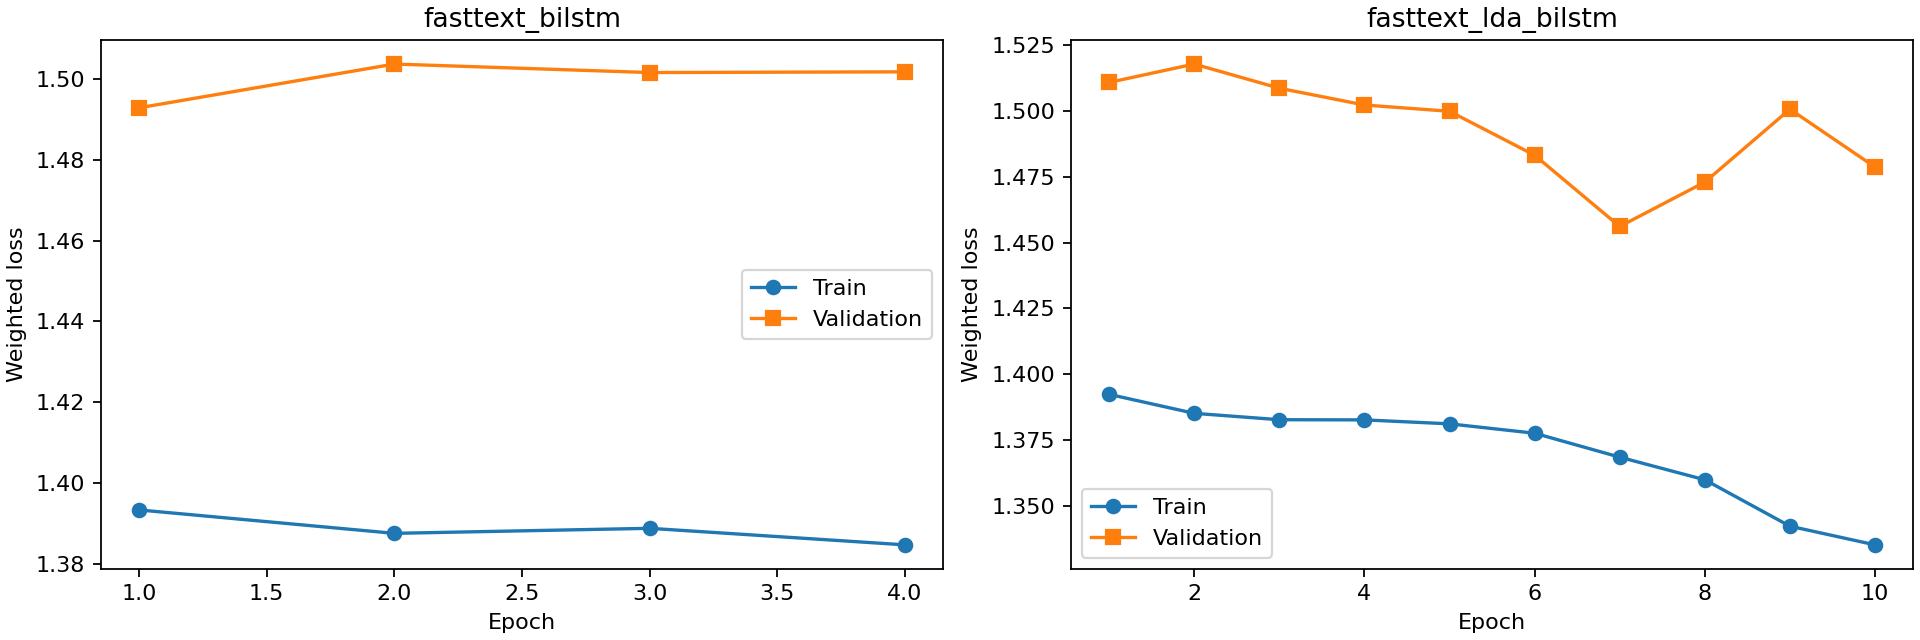

fasttext_bilstm | epoch 1/15 | train=1.3905 | validation=1.5034
fasttext_bilstm | epoch 2/15 | train=1.3860 | validation=1.5067
fasttext_bilstm | epoch 3/15 | train=1.3835 | validation=1.5030
fasttext_bilstm | epoch 4/15 | train=1.3850 | validation=1.5021
fasttext_bilstm | epoch 5/15 | train=1.3834 | validation=1.5017
fasttext_bilstm | epoch 6/15 | train=1.3761 | validation=1.5018
fasttext_bilstm | epoch 7/15 | train=1.3686 | validation=1.4925
fasttext_bilstm | epoch 8/15 | train=1.3597 | validation=1.4795
fasttext_bilstm | epoch 9/15 | train=1.3438 | validation=1.4754
fasttext_bilstm | epoch 10/15 | train=1.3357 | validation=1.4922
fasttext_bilstm | epoch 11/15 | train=1.3270 | validation=1.4810
fasttext_bilstm | epoch 12/15 | train=1.3250 | validation=1.4922
Early stopping; best epoch=9
fasttext_lda_bilstm | epoch 1/15 | train=1.3846 | validation=1.4882
fasttext_lda_bilstm | epoch 2/15 | train=1.3827 | validation=1.4967
fasttext_lda_bilstm | epoch 3/15 | train=1.3800 | validation=1.4

,model,best_epoch,best_validation_loss,epochs_executed,device
0,fasttext_bilstm,9,1.475398,12,cuda
1,fasttext_lda_bilstm,8,1.460571,11,cuda


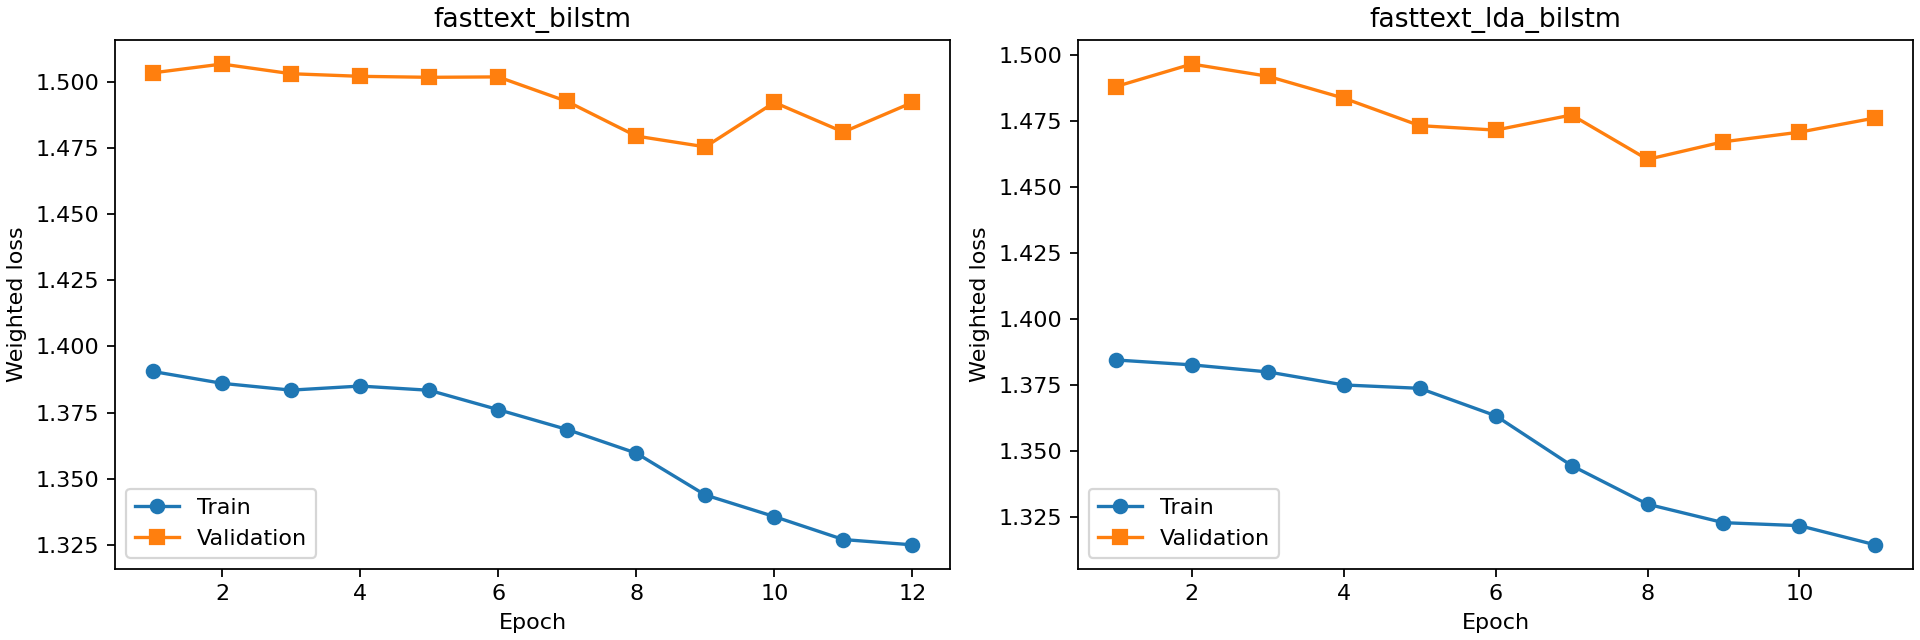

,section,input,proses,output
5,07 Modeling,LDA + embedding + label train/validation,"fit classifier, early stopping validation","seed/model: {42: ['mayoritas', 'tfidf_linear_s..."


In [8]:
from wisata_madura.modeling import run_baselines, run_lda_only, evaluate_classifiers

predictions_by_seed = {SEED: run_baselines(split, seed=SEED)}
predictions_by_seed[SEED].update(run_lda_only(split, topics, seed=SEED))
history_frames = []
if RUN_DEEP:
    for training_seed in training_seeds:
        seed_dir = OUTPUT_DIR / "models" / f"seed_{training_seed}"
        deep_predictions, history = run_bilstm_variants(
            split, topics, encoded_by_seed[training_seed], deep_configs[training_seed], seed_dir)
        predictions_by_seed.setdefault(training_seed, {}).update(deep_predictions)
        history.assign(seed=training_seed).to_csv(seed_dir / "riwayat_bilstm.csv", index=False)
        plot_training_history(history, seed_dir)
        history_frames.append(history.assign(seed=training_seed))
        display(pd.read_csv(seed_dir / "checkpoint_bilstm.csv"))
        display(Image(filename=str(seed_dir / "kurva_bilstm.png")))
    all_history = pd.concat(history_frames, ignore_index=True)
    all_history.to_csv(OUTPUT_DIR / "riwayat_bilstm_semua_seed.csv", index=False)
display(trace.record("07 Modeling", "LDA + embedding + label train/validation", "fit classifier, early stopping validation", f"seed/model: { {seed: list(p) for seed,p in predictions_by_seed.items()} }"))

## 08 · OUTPUT: evaluasi test dan prediksi atribut

**Input:** Prediksi semua model yang telah ditentukan; label test.

**Proses:** Accuracy/micro-F1/macro-F1/Hamming loss per ulasan dan destinasi; ringkasan semua seed.

**Output:** Metrik, dukungan per kelas, prediksi CSV, perbandingan_model.png.

Tidak memilih seed, split, K, atau arsitektur terbaik dari skor test. **Macro-F1 utama memakai seluruh kelas dataset** (kelas tanpa support test ikut bernilai nol); `macro_f1_present` hanya kelas yang muncul di test. Kolom jumlah kelas dan support wajib dibaca. Untuk satu label per atribut, micro-F1=accuracy dan Hamming loss=1−accuracy; bukan tiga bukti independen. Deep full: tiga seed, klasik: satu run; SD seed bukan confidence interval. Dengan hanya beberapa destinasi test dan kelas train-only, tidak ada klaim generalisasi semua kategori. Voting destinasi memakai mayoritas; seri diurutkan label, bukan diputuskan dengan label aktual.

,model,target,unit,runs,macro_f1_mean,macro_f1_std,accuracy_mean,hamming_loss_mean,n
0,fasttext_bilstm,rekomendasi_cuaca,destinasi,3,0.3786,0.1193,0.5000,0.5000,6
2,fasttext_bilstm,wisata,destinasi,3,0.0119,0.0206,0.0556,0.9444,6
4,fasttext_lda_bilstm,rekomendasi_cuaca,destinasi,3,0.3532,0.2767,0.3889,0.6111,6
6,fasttext_lda_bilstm,wisata,destinasi,3,0.0208,0.0361,0.0556,0.9444,6
8,lda_logreg,rekomendasi_cuaca,destinasi,1,0.2500,NaN,0.3333,0.6667,6
10,lda_logreg,wisata,destinasi,1,0.1333,NaN,0.3333,0.6667,6
12,mayoritas,rekomendasi_cuaca,destinasi,1,0.4000,NaN,0.6667,0.3333,6
14,mayoritas,wisata,destinasi,1,0.0625,NaN,0.3333,0.6667,6
16,tfidf_linear_svc,rekomendasi_cuaca,destinasi,1,0.3333,NaN,0.5000,0.5000,6
18,tfidf_linear_svc,wisata,destinasi,1,0.2250,NaN,0.5000,0.5000,6


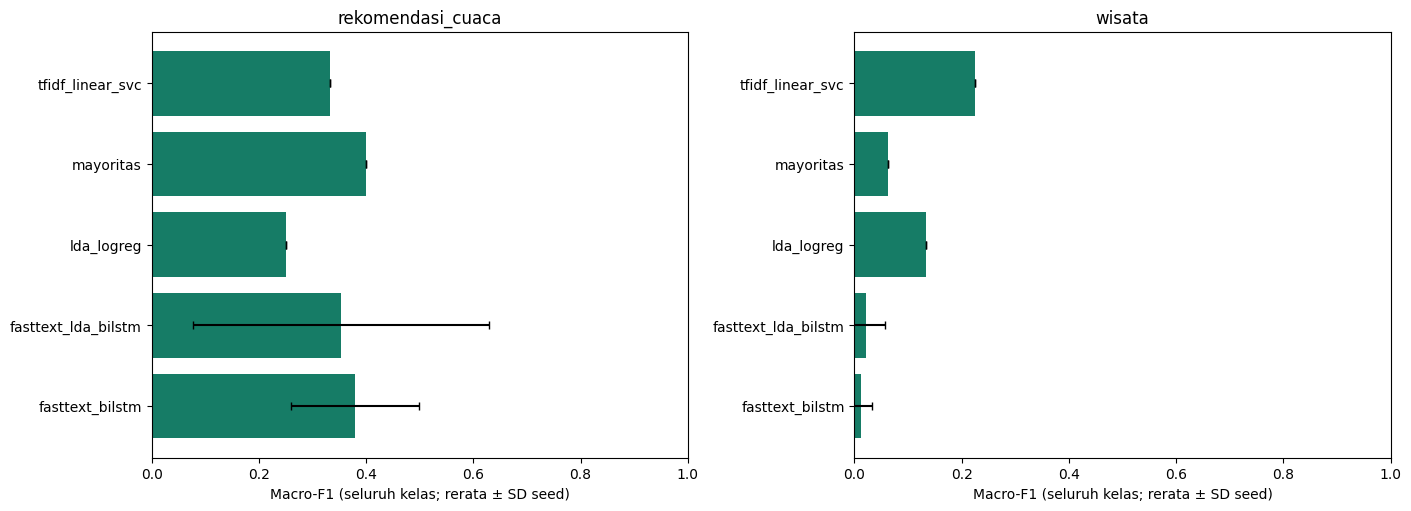

,target,model,unit,kelas,precision,recall,f1-score,support,seed
2,rekomendasi_cuaca,mayoritas,destinasi,Kemarau,0.666667,1.0,0.8,4.0,42
3,rekomendasi_cuaca,mayoritas,destinasi,Kemarau & Penghujan,0.000000,0.0,0.0,2.0,42
12,wisata,mayoritas,destinasi,air terjun,0.000000,0.0,0.0,0.0,42
13,wisata,mayoritas,destinasi,hutan/perkebunan,0.000000,0.0,0.0,0.0,42
14,wisata,mayoritas,destinasi,lainnya,0.000000,0.0,0.0,0.0,42
...,...,...,...,...,...,...,...,...,...
175,wisata,fasttext_lda_bilstm,destinasi,pantai,0.000000,0.0,0.0,2.0,44
176,wisata,fasttext_lda_bilstm,destinasi,pegunungan,0.000000,0.0,0.0,1.0,44
177,wisata,fasttext_lda_bilstm,destinasi,religi,0.000000,0.0,0.0,1.0,44
178,wisata,fasttext_lda_bilstm,destinasi,sejarah,0.000000,0.0,0.0,1.0,44


,section,input,proses,output
6,08 Evaluasi,prediksi tetap + label test,nilai semua run; tidak memilih pemenang seed,36 baris metrik + prediksi CSV


In [9]:
from wisata_madura.reporting import export_predictions, summarize_seed_metrics
label_space = {target: sorted(reviews[target].unique()) for target in TARGETS}
metric_frames, detail_frames = [], []
for training_seed, predictions in predictions_by_seed.items():
    metrics, details = evaluate_classifiers(split.test, predictions, label_space=label_space)
    metric_frames.append(metrics.assign(seed=training_seed))
    detail_frames.append(details.assign(seed=training_seed))
    prediction_dir = OUTPUT_DIR / "predictions" / f"seed_{training_seed}"
    prediction_dir.mkdir(parents=True, exist_ok=True)
    export_predictions(split.test, predictions, prediction_dir)
metrics = pd.concat(metric_frames, ignore_index=True)
per_class = pd.concat(detail_frames, ignore_index=True)
metrics.to_csv(OUTPUT_DIR / "metrik_klasifikasi.csv", index=False)
per_class.to_csv(OUTPUT_DIR / "metrik_per_kelas.csv", index=False)
summary, figure = summarize_seed_metrics(metrics, OUTPUT_DIR)
display(summary.loc[summary.unit.eq("destinasi")].round(4))
display(figure)
plt.close(figure)
display(per_class.loc[per_class.unit.eq("destinasi")])
display(trace.record("08 Evaluasi", "prediksi tetap + label test", "nilai semua run; tidak memilih pemenang seed", f"{len(metrics)} baris metrik + prediksi CSV"))

## 09 · OUTPUT: provenance, konfigurasi, dan unduhan

**Input:** Audit, parameter, hash kode, seed, seluruh keluaran run.

**Proses:** Simpan manifest dan ringkasan kontrak Input–Proses–Output.

**Output:** audit_dataset.json, daftar_output.txt, tabel alur, arsip ZIP.

Folder keluaran smoke tidak boleh dikutip sebagai eksperimen penuh. BGE/Streamlit adalah tahap rekomendasi terpisah dari klasifikasi atribut pada notebook ini. Kualitas ranking memerlukan penilaian relevansi independen; skor klasifikasi tidak membuktikan kualitas rekomendasi.

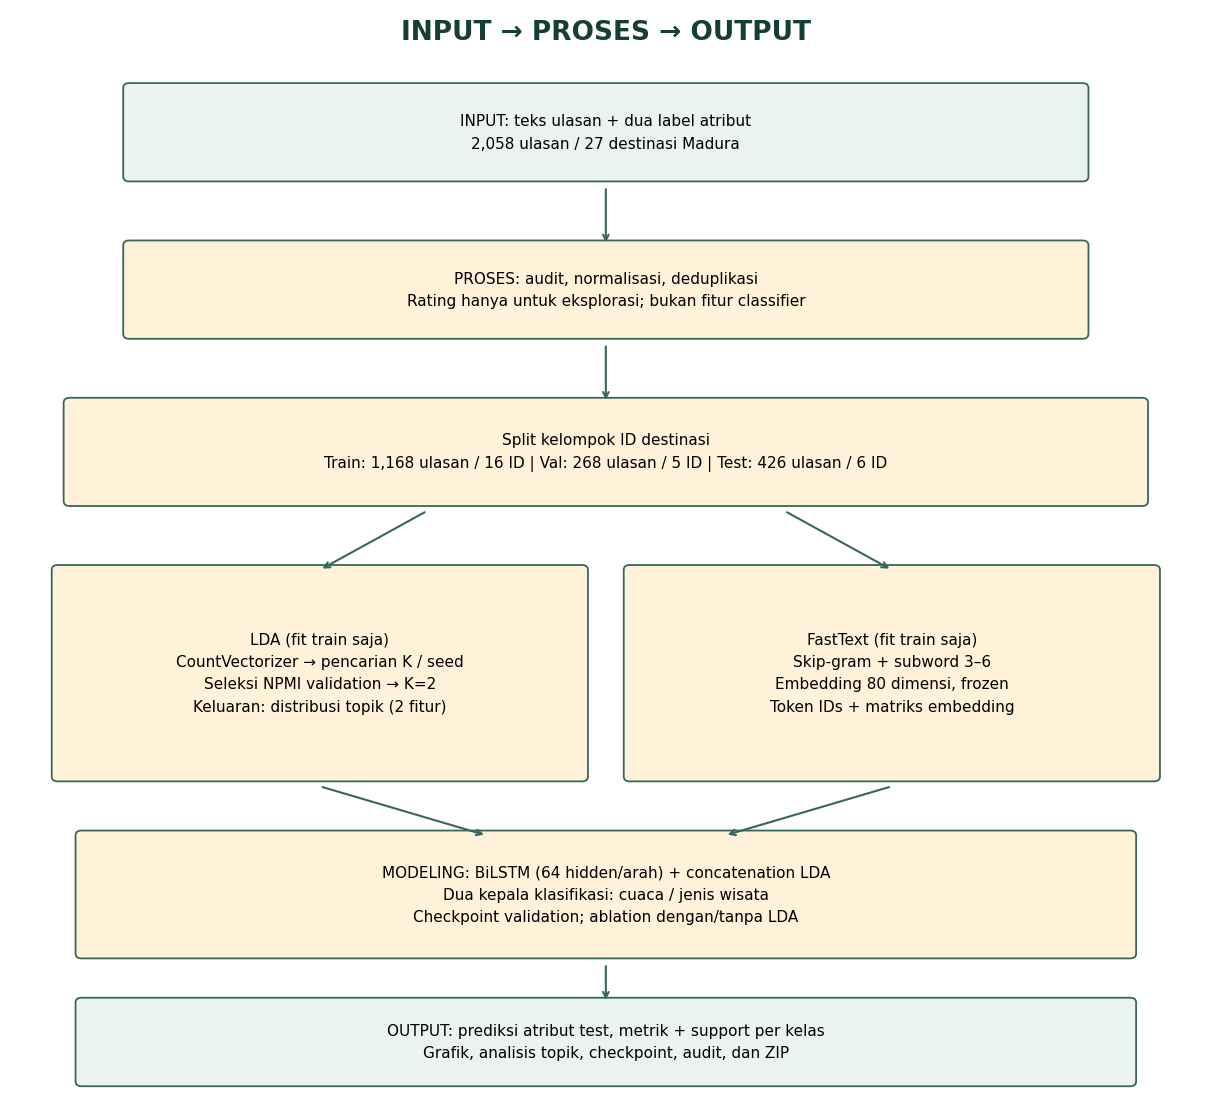

,section,input,proses,output
0,01 Input,dataset_madura_bersih.xlsx,validasi + normalisasi,"reviews (2058, 9)"
1,02 Audit/EDA,2058 ulasan,audit + agregasi per unit,EDA PNG/CSV + audit
2,03 Split,2058 ulasan,kelompok ID + metadata; tanpa skor,"{'train': 1168, 'validation': 268, 'test': 426}"
3,04 LDA,"train=1168, validation=268",fit count/LDA di train; seleksi validation,"K=2; theta=(1168, 2)"
4,06 Embedding,1168 ulasan train,"FastText train-only, satu kali per seed",3 embedding beku
5,07 Modeling,LDA + embedding + label train/validation,"fit classifier, early stopping validation","seed/model: {42: ['mayoritas', 'tfidf_linear_s..."
6,08 Evaluasi,prediksi tetap + label test,nilai semua run; tidak memilih pemenang seed,36 baris metrik + prediksi CSV


OUTPUT: /content/hasil_wisata_madura_v3/20261112-131554-444000
Arsip: /content/hasil_wisata_madura_v3/20261112-131554-444000.zip
alur_input_proses_output.csv
alur_pipeline.png
audit_dataset.json
audit_lda.json
audit_split.json
bobot_kata_topik.csv
cakupan_kelas_partisi.csv
contoh_ulasan_topik.csv
distribusi_topik_dokumen_latih.csv
eda_cuaca_destinasi.csv
eda_cuaca_ulasan.csv
eda_jenis_destinasi.csv
eda_rating.csv
eda_rating_cuaca_jenis.png
heatmap_topik_cuaca.png
histogram_panjang_ulasan.png
id_partisi_test.csv
id_partisi_train.csv
id_partisi_validation.csv
kata_utama_topik.png
kualitas_topik.csv
metrik_klasifikasi.csv
metrik_per_kelas.csv
model_lda.joblib
models/seed_42/checkpoint_bilstm.csv
models/seed_42/embedding_matrix.npy
models/seed_42/fasttext.model
models/seed_42/fasttext_bilstm.pt
models/seed_42/fasttext_lda_bilstm.pt
models/seed_42/kurva_bilstm.png
models/seed_42/riwayat_bilstm.csv
models/seed_42/token_ids.json
models/seed_43/checkpoint_bilstm.csv
models/seed_43/embedding_ma

In [10]:
from importlib.metadata import version
from wisata_madura.reporting import save_run_manifest, plot_pipeline_flow
import shutil
flow_figure = plot_pipeline_flow(reviews, split, lda_audit, next(iter(deep_configs.values()), None), OUTPUT_DIR)
display(flow_figure)
plt.close(flow_figure)
packages = ["numpy", "pandas", "scikit-learn", "openpyxl", "matplotlib"]
if RUN_DEEP:
    packages += ["gensim", "torch"]
audit.update(dict(pipeline_version="3.0", mode=MODE, run_deep=RUN_DEEP,
                  geography="Madura; owner-confirmed dataset", source_commit=source_commit, source_working_tree_dirty=source_dirty,
                  source_module_sha256=source_hashes, split=split.audit, lda=lda_audit,
                  deep_config={str(seed): asdict(config) for seed,config in deep_configs.items()},
                  packages={package: version(package) for package in packages},
                  metric_label_space=label_space))
display(pd.DataFrame(trace.rows))
files = save_run_manifest(OUTPUT_DIR, audit)
archive = shutil.make_archive(str(OUTPUT_DIR), "zip", root_dir=OUTPUT_DIR)
print("OUTPUT:", OUTPUT_DIR.resolve())
print("Arsip:", archive)
print("\n".join(files))
# Opsional unduh di Google Colab:
# from google.colab import files
# files.download(archive)